# De onde vem o desempenho em manutenção preditiva? — Desenho fatorial no AI4I 2020

Notebook completo do estudo proposto. Cada experimento responde a uma limitação ou sugestão de trabalho futuro declarada na literatura recente com a mesma base.

| Exp. | O que testa | Lacuna da literatura |
|---|---|---|
| 1 | Desenho fatorial: protocolo × representação × balanceamento × modelo, com ANOVA | Su & Tseng (2026); Hosseinzadeh et al. (2023); Trisatya & Haryoko (2026) |
| 2 | Circularidade: features construídas automaticamente, sem conhecimento de domínio | Pan et al. (2026) |
| 3 | Ablação: contribuição de cada feature física, por modo de falha | Pan et al. (2026); Zhao et al. (2025) |
| 4 | Robustez a ruído de medição | Autran et al. (2024) |
| 5 | Robustez a dados faltantes | Autran et al. (2024) |
| 6 | Ajuste de hiperparâmetros vs. configuração padrão | Qahtani (2026) |
| 7 | Recuperação das regras do gerador e complexidade necessária | Hosseinzadeh et al. (2023); Pan et al. (2026) |
| 1.1 | Dependência entre registros (justifica a divisão temporal) | Saha et al. (2026) |
| 8 | HDF com protocolo aleatório (circularidade, robustez, complexidade) | Pan et al. (2026); Autran et al. (2024) |

**Como rodar**
- **Colab ou Jupyter.** Coloque `manutencao_preditiva.csv` na mesma pasta, ou deixe o notebook baixar a base original da UCI.
- **Teste rápido primeiro:** `MODO_RAPIDO = True` roda tudo em poucos minutos, com menos repetições. Depois mude para `False`.
- **Checkpoint:** cada experimento salva um CSV a cada combinação concluída, em `resultados_fatorial/`. Se a execução cair, rode de novo; o que já foi feito é pulado.
- **Sem vazamento:** a construção das features, a imputação, a padronização e o SMOTE ficam dentro do pipeline e são ajustados só no treino. O limiar de decisão é escolhido numa fatia de validação do treino.

In [1]:
# !pip install -q imbalanced-learn statsmodels      # descomente no Colab, se necessário
import os, io, zipfile, urllib.request, warnings, time, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, matthews_corrcoef, f1_score, precision_recall_curve
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy.stats import randint, loguniform
warnings.filterwarnings('ignore')

# ---------------- configuração ----------------
MODO_RAPIDO = False                     # True = teste em poucos minutos
SEED   = 42
SAIDA  = 'resultados_fatorial'
os.makedirs(SAIDA, exist_ok=True)

CORTES_TEMPORAIS = [0.5, 0.6, 0.7, 0.8] if not MODO_RAPIDO else [0.7]
SEMENTES_ALEAT   = [0, 1, 2, 3]         if not MODO_RAPIDO else [0]
ALVOS            = ['failure', 'HDF', 'PWF', 'OSF', 'TWF'] if not MODO_RAPIDO else ['failure', 'PWF', 'HDF']
N_ARVORES        = 200 if not MODO_RAPIDO else 40
N_ITER_BUSCA     = 15  if not MODO_RAPIDO else 3
print('Modo rápido' if MODO_RAPIDO else 'Modo completo', '| saída em', SAIDA)

Modo completo | saída em resultados_fatorial


## 1. Dados

In [2]:
ARQ_PT = 'manutencao_preditiva.csv'
URL = 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip'
if os.path.exists(ARQ_PT):
    raw = pd.read_csv(ARQ_PT)
    df = raw.rename(columns={'Tipo': 'Type', 'Temperatura Ar [K]': 'air', 'Temperatura Processo [K]': 'proc',
                             'Velocidade Rotacao [rpm]': 'rpm', 'Torque [Nm]': 'torque',
                             'Desgaste Ferramenta [min]': 'wear', 'Alvo': 'failure'})
    tf = raw['Tipo da Falha'].astype(str).str.lower()
    for k, s in [('HDF', 'heat'), ('PWF', 'power'), ('OSF', 'overstrain'), ('TWF', 'tool'), ('RNF', 'random')]:
        df[k] = tf.str.contains(s).astype(int)
    fonte = ARQ_PT
else:
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
    raw = pd.read_csv(z.open('ai4i2020.csv'))
    df = raw.rename(columns={'Air temperature [K]': 'air', 'Process temperature [K]': 'proc',
                             'Rotational speed [rpm]': 'rpm', 'Torque [Nm]': 'torque',
                             'Tool wear [min]': 'wear', 'Machine failure': 'failure'})
    fonte = 'UCI (original)'
df = df.sort_values('UDI').reset_index(drop=True)
SENSORES = ['air', 'proc', 'rpm', 'torque', 'wear']
DADOS = df[SENSORES + ['Type']].copy()
print('Fonte:', fonte, '| registros:', len(df))
print(df[['failure', 'HDF', 'PWF', 'OSF', 'TWF', 'RNF']].sum().to_dict())

Fonte: UCI (original) | registros: 10000
{'failure': 339, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'TWF': 46, 'RNF': 19}


### 1.1 Os registros são independentes?

Alguns trabalhos tratam o AI4I como registros independentes (por exemplo, Saha et al., 2026). Se registros vizinhos forem correlacionados, a divisão aleatória coloca quase-cópias no treino e no teste e infla o desempenho, e a divisão temporal é necessária. A autocorrelação por ordem de UDI responde a isso; a coluna "embaralhado" mostra o valor esperado se os registros fossem independentes.

In [3]:
ac = pd.DataFrame({'lag 1': [df[c].autocorr(1) for c in SENSORES],
                   'lag 50': [df[c].autocorr(50) for c in SENSORES],
                   'embaralhado (lag 1)': [df[c].sample(frac=1, random_state=SEED).reset_index(drop=True).autocorr(1) for c in SENSORES]},
                  index=SENSORES).round(3)
ac.to_csv(os.path.join(SAIDA, 'autocorrelacao.csv')); display(ac)

,lag 1,lag 50,embaralhado (lag 1)
air,0.999,0.982,-0.018
proc,0.999,0.948,-0.020
rpm,0.008,-0.015,0.020
torque,0.005,-0.008,0.015
wear,0.931,-0.430,0.011


## 2. Representações das variáveis (dentro do pipeline)

- **brutas:** 5 sensores + tipo de produto.
- **físicas:** brutas + ΔT (processo − ar), potência (torque × ω), desgaste × torque e desgaste × torque normalizado pelo limiar do tipo.
- **automáticas:** brutas + soma, diferença, produto e razão de **todos** os pares de sensores (40 features), **sem conhecimento de domínio**. Se o modelo redescobrir sozinho ΔT, potência e desgaste × torque, o ganho não depende de conhecermos as regras (teste de circularidade).

A imputação de faltantes (mediana do treino) é feita antes de construir as features, como aconteceria na prática.

In [4]:
FISICAS_TODAS = ['dT', 'power', 'strain', 'strain_rel']
LIMIAR_OSF = {'L': 11000, 'M': 12000, 'H': 13000}

class Representacao(BaseEstimator, TransformerMixin):
    def __init__(self, modo='brutas', extras=None):
        self.modo, self.extras = modo, extras
    def fit(self, X, y=None):
        self.mediana_ = X[SENSORES].median()
        return self
    def _construir(self, X):
        Z = X[SENSORES].astype(float).fillna(self.mediana_)
        F = Z.copy()
        F['type_M'] = (X['Type'] == 'M').astype(float); F['type_H'] = (X['Type'] == 'H').astype(float)
        if self.modo == 'fisicas':
            fis = {'dT': Z['proc'] - Z['air'],
                   'power': Z['torque'] * Z['rpm'] * 2 * np.pi / 60,
                   'strain': Z['wear'] * Z['torque'],
                   'strain_rel': Z['wear'] * Z['torque'] / X['Type'].map(LIMIAR_OSF).astype(float)}
            for k in (self.extras if self.extras is not None else FISICAS_TODAS):
                F[k] = fis[k]
        elif self.modo == 'auto':
            for a, b in itertools.combinations(SENSORES, 2):
                F[f'{a}+{b}'] = Z[a] + Z[b];  F[f'{a}-{b}'] = Z[a] - Z[b]
                F[f'{a}*{b}'] = Z[a] * Z[b];  F[f'{a}/{b}'] = Z[a] / (Z[b].abs() + 1e-6)
        return F
    def transform(self, X):
        return self._construir(X).values
    def nomes(self, X):
        return list(self._construir(X.iloc[:5]).columns)

print({m: len(Representacao(m).fit(DADOS).nomes(DADOS)) for m in ['brutas', 'fisicas', 'auto']})

{'brutas': 7, 'fisicas': 11, 'auto': 47}


## 3. Protocolos, modelos e avaliação

- **Protocolo temporal:** treino = fração inicial da série (cortes de 50%, 60%, 70% e 80%); teste = restante.
- **Protocolo aleatório:** divisão estratificada 70/30, com 4 sementes. É o protocolo usado pela maior parte da literatura.
- **Limiar:** escolhido para maximizar o F1 numa fatia de validação (últimos 20% do treino no temporal; 20% estratificado no aleatório). O modelo final é reajustado no treino inteiro.
- **Métricas:** PR-AUC (independe de limiar; métrica principal), MCC e F1 no limiar escolhido.

In [5]:
def divisoes(alvo):
    y = df[alvo].values
    for c in CORTES_TEMPORAIS:
        k = int(c * len(df))
        yield 'temporal', f'corte {int(c*100)}%', np.arange(k), np.arange(k, len(df))
    for s in SEMENTES_ALEAT:
        tr, te = train_test_split(np.arange(len(df)), test_size=0.3, stratify=y, random_state=s)
        yield 'aleatorio', f'semente {s}', np.sort(tr), np.sort(te)

def modelo(nome, balanc):
    cw = balanc == 'class_weight'
    if nome == 'Logística':
        return LogisticRegression(max_iter=3000, class_weight='balanced' if cw else None)
    if nome == 'Árvore rasa':
        return DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEED,
                                      class_weight='balanced' if cw else None)
    if nome == 'Random Forest':
        return RandomForestClassifier(N_ARVORES, min_samples_leaf=2, n_jobs=-1, random_state=SEED,
                                      class_weight='balanced_subsample' if cw else None)
    if nome == 'Gradient Boosting':
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED,
                                              class_weight='balanced' if cw else None)

def pipeline(rep, nome, balanc, n_pos, extras=None):
    passos = [('rep', Representacao(rep, extras))]
    if nome == 'Logística':
        passos.append(('sc', StandardScaler()))
    if balanc == 'smote':
        passos.append(('sm', SMOTE(k_neighbors=max(1, min(5, n_pos - 1)), random_state=SEED)))
    passos.append(('m', modelo(nome, balanc)))
    return Pipeline(passos)

def fatia_validacao(idx_tr, y_tr, protocolo):
    if protocolo == 'temporal':
        k = int(0.8 * len(idx_tr)); return idx_tr[:k], idx_tr[k:]
    try:
        a, b = train_test_split(idx_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
    except ValueError:
        a, b = train_test_split(idx_tr, test_size=0.2, random_state=SEED)
    return np.sort(a), np.sort(b)

def avaliar(X, y, idx_tr, idx_te, protocolo, construtor):
    """construtor(n_pos) -> pipeline novo. Devolve dicionário de métricas no teste."""
    y_tr, y_te = y[idx_tr], y[idx_te]
    n_pos = int(y_tr.sum())
    if n_pos < 6 or y_te.sum() == 0:
        return None
    # limiar escolhido na validação
    sub, val = fatia_validacao(idx_tr, y_tr, protocolo)
    t = 0.5
    if y[val].sum() > 0 and y[sub].sum() >= 6:
        p = construtor(int(y[sub].sum())).fit(X.iloc[sub], y[sub])
        s_val = p.predict_proba(X.iloc[val])[:, 1]
        pr, rc, th = precision_recall_curve(y[val], s_val)
        f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
        t = float(th[np.argmax(f1[:-1])]) if len(th) else 0.5
    p = construtor(n_pos).fit(X.iloc[idx_tr], y_tr)
    s = p.predict_proba(X.iloc[idx_te])[:, 1]
    pred = (s >= t).astype(int)
    return {'PR_AUC': average_precision_score(y_te, s), 'MCC': matthews_corrcoef(y_te, pred),
            'F1': f1_score(y_te, pred, zero_division=0), 'limiar': t,
            'pos_treino': n_pos, 'pos_teste': int(y_te.sum())}

def rodar(nome_arquivo, combinacoes, funcao):
    """Executa combinações com checkpoint. combinacoes: lista de dicts (chaves = colunas)."""
    arq = os.path.join(SAIDA, nome_arquivo)
    if not combinacoes:
        print(f'{nome_arquivo}: nenhuma combinação'); return pd.DataFrame()
    feitos = pd.read_csv(arq) if os.path.exists(arq) else pd.DataFrame()
    chaves = list(combinacoes[0].keys())
    ja = set(map(tuple, feitos[chaves].astype(str).values)) if len(feitos) else set()
    linhas, t0, n = [], time.time(), 0
    for c in combinacoes:
        if tuple(str(c[k]) for k in chaves) in ja:
            continue
        r = funcao(c)
        linhas.append({**c, **(r or {'PR_AUC': np.nan})})
        n += 1
        if n % 20 == 0:
            pd.concat([feitos, pd.DataFrame(linhas)]).to_csv(arq, index=False)
            print(f'  {nome_arquivo}: {n} novas combinações, {time.time()-t0:.0f}s', flush=True)
    res = pd.concat([feitos, pd.DataFrame(linhas)], ignore_index=True)
    res.to_csv(arq, index=False)
    print(f'{nome_arquivo}: {len(res)} linhas ({n} novas em {time.time()-t0:.0f}s)')
    return res

## Experimento 1 — Desenho fatorial

Fatores: **protocolo** (temporal, aleatório) × **representação** (brutas, físicas, automáticas) × **balanceamento** (nenhum, class_weight, SMOTE) × **modelo** (logística, árvore rasa, Random Forest, Gradient Boosting) = 72 combinações, repetidas em 4 divisões por protocolo, para cada alvo (falha agregada e cada modo de falha).

In [6]:
REPS, BALS = ['brutas', 'fisicas', 'auto'], ['nenhum', 'class_weight', 'smote']
MODELOS = ['Logística', 'Árvore rasa', 'Random Forest', 'Gradient Boosting']
combs, mapa_div = [], {}
for alvo in ALVOS:
    for prot, rep_div, tr, te in divisoes(alvo):
        mapa_div[(alvo, prot, rep_div)] = (tr, te)
        for rep in REPS:
            for bal in BALS:
                for m in MODELOS:
                    combs.append({'alvo': alvo, 'protocolo': prot, 'divisao': rep_div,
                                  'representacao': rep, 'balanceamento': bal, 'modelo': m})
print(len(combs), 'combinações')

def f_exp1(c):
    tr, te = mapa_div[(c['alvo'], c['protocolo'], c['divisao'])]
    y = df[c['alvo']].values
    return avaliar(DADOS, y, tr, te, c['protocolo'],
                   lambda n: pipeline(c['representacao'], c['modelo'], c['balanceamento'], n))

exp1 = rodar('exp1_fatorial.csv', combs, f_exp1)

1440 combinações


  exp1_fatorial.csv: 20 novas combinações, 17s


  exp1_fatorial.csv: 40 novas combinações, 54s


  exp1_fatorial.csv: 60 novas combinações, 71s


  exp1_fatorial.csv: 80 novas combinações, 105s


  exp1_fatorial.csv: 100 novas combinações, 127s


... (64 outputs left out)

  exp1_fatorial.csv: 1400 novas combinações, 1462s


  exp1_fatorial.csv: 1420 novas combinações, 1484s


  exp1_fatorial.csv: 1440 novas combinações, 1520s


exp1_fatorial.csv: 1440 linhas (1440 novas em 1520s)


### Análise do Experimento 1 — quanto cada fator explica

ANOVA (tipo II) por alvo, com a repetição (1ª a 4ª divisão de cada protocolo) como bloco cruzado. **η² = parcela da variação total do PR-AUC explicada por cada fator ou interação.**

HDF: só um protocolo tem casos positivos no teste; o efeito do protocolo não é estimado


,failure η²,failure p,HDF η²,HDF p,PWF η²,PWF p,OSF η²,OSF p,TWF η²,TWF p
protocolo,0.068,0.000,NaN,NaN,0.003,0.029,0.000,0.285,0.179,0.000
representacao,0.103,0.000,0.177,0.000,0.453,0.000,0.330,0.000,0.005,0.222
balanceamento,0.019,0.000,0.002,0.011,0.003,0.148,0.003,0.005,0.025,0.001
modelo,0.644,0.000,0.389,0.000,0.099,0.000,0.206,0.000,0.238,0.000
protocolo:representacao,0.000,0.429,NaN,NaN,0.005,0.027,0.001,0.369,0.002,0.596
protocolo:modelo,0.001,0.160,NaN,NaN,0.017,0.000,0.001,0.594,0.047,0.000
representacao:balanceamento,0.002,0.068,0.006,0.000,0.004,0.208,0.013,0.000,0.000,0.993
representacao:modelo,0.077,0.000,0.391,0.000,0.159,0.000,0.357,0.000,0.005,0.813
balanceamento:modelo,0.012,0.000,0.004,0.014,0.054,0.000,0.015,0.000,0.020,0.085
Residual,0.069,NaN,0.029,NaN,0.182,NaN,0.070,NaN,0.462,NaN


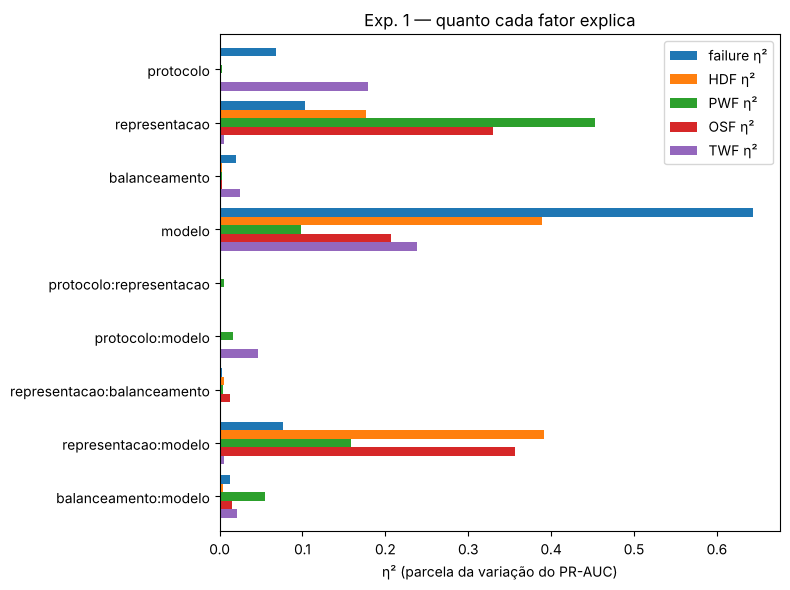

In [7]:
def anova_alvo(d, metrica='PR_AUC'):
    # ANOVA tipo II. A repetição (1ª a 4ª divisão) entra como bloco cruzado com o protocolo,
    # e não aninhado nele, para não confundir o efeito do protocolo. Fatores com um único nível
    # (ex.: HDF sem casos no teste temporal) são retirados automaticamente.
    d = d.dropna(subset=[metrica]).copy()
    # número da repetição dentro de cada protocolo (cortes temporais e sementes viram 1..4)
    d['repeticao'] = d.groupby('protocolo')['divisao'].transform(lambda s: s.astype('category').cat.codes + 1)
    fatores = [f for f in ['protocolo', 'representacao', 'balanceamento', 'modelo'] if d[f].nunique() > 1]
    termos = [f'C({f})' for f in fatores]
    pares = [('protocolo', 'representacao'), ('protocolo', 'modelo'), ('representacao', 'balanceamento'),
             ('representacao', 'modelo'), ('balanceamento', 'modelo')]
    termos += [f'C({a}):C({b})' for a, b in pares if a in fatores and b in fatores]
    if d['repeticao'].nunique() > 1:
        termos.append('C(repeticao)')
    a = anova_lm(smf.ols(f'{metrica} ~ ' + ' + '.join(termos), d).fit(), typ=2)
    a['eta2'] = a['sum_sq'] / a['sum_sq'].sum()
    return a

tabelas = []
for alvo in ALVOS:
    d = exp1[exp1.alvo == alvo]
    if d['PR_AUC'].notna().sum() < 30:
        print(f'{alvo}: poucas avaliações válidas, ANOVA não calculada'); continue
    if d.dropna(subset=['PR_AUC'])['protocolo'].nunique() < 2:
        print(f'{alvo}: só um protocolo tem casos positivos no teste; o efeito do protocolo não é estimado')
    a = anova_alvo(d)
    a = a.drop(index=[i for i in a.index if 'repeticao' in i])
    t = a[['eta2', 'PR(>F)']].rename(index=lambda s: s.replace('C(', '').replace(')', ''))
    t.columns = [f'{alvo} η²', f'{alvo} p']
    tabelas.append(t)
eta = pd.concat(tabelas, axis=1)
eta.to_csv(os.path.join(SAIDA, 'exp1_anova_eta2.csv'))
display(eta.round(3))

# Figura: η² dos efeitos principais e interações, por alvo
cols = [c for c in eta.columns if 'η²' in c]
ax = eta[cols].drop(index='Residual').plot.barh(figsize=(8, 6), width=0.8)
ax.set_xlabel('η² (parcela da variação do PR-AUC)'); ax.set_title('Exp. 1 — quanto cada fator explica')
ax.invert_yaxis(); plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'fig_exp1_eta2.png'), dpi=200); plt.show()

PR_AUC           MCC       
            mean    std   mean    std
protocolo                            
aleatorio  0.692  0.187  0.672  0.169
temporal   0.592  0.184  0.563  0.201

PR_AUC           MCC       
                mean    std   mean    std
representacao                            
auto           0.673  0.181  0.647  0.183
brutas         0.557  0.171  0.513  0.151
fisicas        0.697  0.195  0.692  0.198

PR_AUC           MCC       
                mean    std   mean    std
balanceamento                            
class_weight   0.658  0.197  0.633  0.195
nenhum         0.664  0.176  0.645  0.188
smote          0.605  0.199  0.574  0.192

PR_AUC           MCC       
                    mean    std   mean    std
modelo                                       
Gradient Boosting  0.801  0.077  0.743  0.133
Logística          0.422  0.072  0.396  0.081
Random Forest      0.770  0.099  0.707  0.148
Árvore rasa        0.576  0.179  0.623  0.177

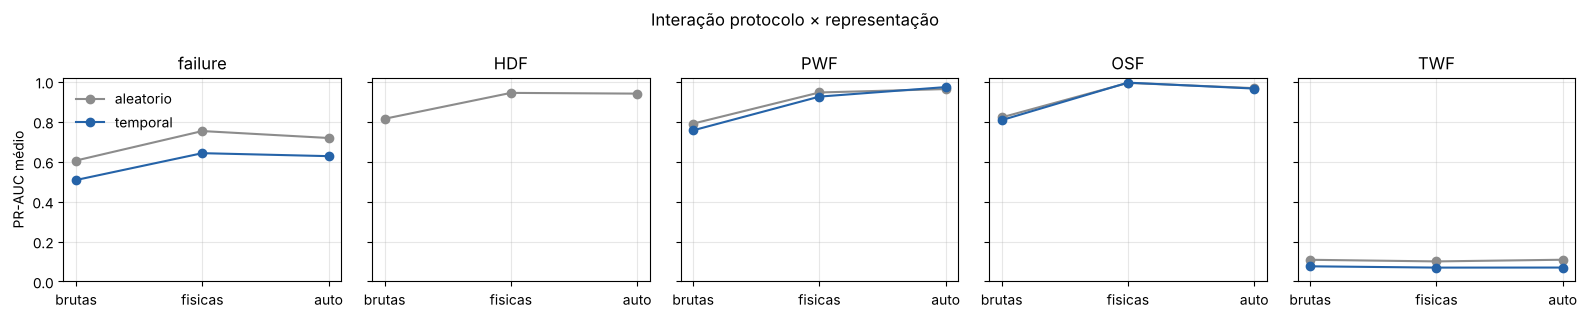

representacao      ganho_fisicas  ganho_auto
alvo    protocolo                           
HDF     aleatorio          0.130       0.126
        temporal             NaN         NaN
OSF     aleatorio          0.173       0.146
        temporal           0.188       0.158
PWF     aleatorio          0.156       0.173
        temporal           0.169       0.217
TWF     aleatorio         -0.008       0.000
        temporal          -0.007      -0.006
failure aleatorio          0.147       0.113
        temporal           0.134       0.119

In [8]:
# Médias por fator (falha agregada) e a interação protocolo × representação
d = exp1[exp1.alvo == 'failure']
for fator in ['protocolo', 'representacao', 'balanceamento', 'modelo']:
    display(d.groupby(fator)[['PR_AUC', 'MCC']].agg(['mean', 'std']).round(3))

fig, axs = plt.subplots(1, len(ALVOS), figsize=(3.2 * len(ALVOS), 3.2), sharey=True)
for ax, alvo in zip(np.atleast_1d(axs), ALVOS):
    g = exp1[exp1.alvo == alvo].groupby(['protocolo', 'representacao'])['PR_AUC'].mean().unstack()
    for prot, cor in [('aleatorio', '#8C8C8C'), ('temporal', '#2563A8')]:
        if prot in g.index:
            ax.plot(REPS, g.loc[prot, REPS], 'o-', color=cor, label=prot)
    ax.set_title(alvo); ax.set_ylim(0, 1.02); ax.grid(alpha=.3)
np.atleast_1d(axs)[0].set_ylabel('PR-AUC médio'); np.atleast_1d(axs)[0].legend(frameon=False)
fig.suptitle('Interação protocolo × representação'); plt.tight_layout()
plt.savefig(os.path.join(SAIDA, 'fig_exp1_interacao.png'), dpi=200); plt.show()

# Ganho das features físicas sobre as brutas, por protocolo (compara com Pan et al., 2026)
piv = exp1.groupby(['alvo', 'protocolo', 'modelo', 'balanceamento', 'representacao'])['PR_AUC'].mean().unstack()
piv['ganho_fisicas'] = piv['fisicas'] - piv['brutas']
piv['ganho_auto'] = piv['auto'] - piv['brutas']
ganho = piv.groupby(['alvo', 'protocolo'])[['ganho_fisicas', 'ganho_auto']].mean().round(3)
ganho.to_csv(os.path.join(SAIDA, 'exp1_ganho_por_protocolo.csv')); display(ganho)

## Experimento 2 — Circularidade: o modelo redescobre as features físicas sozinho?

Na representação automática há 40 combinações de pares de sensores. Entre elas estão, sem destaque, `proc-air` (ΔT), `rpm*torque` (∝ potência) e `torque*wear` (desgaste × torque). A importância por permutação é medida numa fatia de validação do treino (o teste não é usado). Se essas três aparecem no topo, o modelo as encontrou sem conhecimento de domínio.

In [9]:
ALVO_FIS = {'HDF': 'air-proc', 'PWF': 'rpm*torque', 'OSF': 'torque*wear', 'TWF': 'wear', 'failure': None}
linhas = []
k = int(0.7 * len(df))
for alvo in ALVOS:
    y = df[alvo].values; tr = np.arange(k); sub, val = tr[:int(0.8 * k)], tr[int(0.8 * k):]
    if y[sub].sum() < 6 or y[val].sum() == 0: continue
    p = pipeline('auto', 'Random Forest', 'class_weight', int(y[sub].sum())).fit(DADOS.iloc[sub], y[sub])
    nomes = p.named_steps['rep'].nomes(DADOS)
    # importância por permutação sobre as features construídas
    Xv = p.named_steps['rep'].transform(DADOS.iloc[val])
    imp = permutation_importance(p.named_steps['m'], Xv, y[val], scoring='average_precision',
                                 n_repeats=5 if not MODO_RAPIDO else 2, random_state=SEED, n_jobs=-1)
    ordem = pd.Series(imp.importances_mean, index=nomes).sort_values(ascending=False)
    top = ordem.head(8)
    linhas.append({'alvo': alvo, 'top 8 (importância por permutação)': ', '.join(f'{n} ({v:.3f})' for n, v in top.items()),
                   'posição de ΔT (air-proc)': int(list(ordem.index).index('air-proc')) + 1,
                   'posição de rpm*torque': int(list(ordem.index).index('rpm*torque')) + 1,
                   'posição de torque*wear': int(list(ordem.index).index('torque*wear')) + 1})
exp2 = pd.DataFrame(linhas); exp2.to_csv(os.path.join(SAIDA, 'exp2_circularidade.csv'), index=False)
pd.set_option('display.max_colwidth', 200); display(exp2)

,alvo,top 8 (importância por permutação),posição de ΔT (air-proc),posição de rpm*torque,posição de torque*wear
0,failure,"rpm*torque (0.104), air+torque (0.020), air/torque (0.018), air-torque (0.015), proc-torque (0.015), proc/torque (0.014), torque (0.007), proc+torque (0.006)",28,1,46
1,PWF,"rpm*torque (0.227), proc-rpm (0.000), rpm/torque (0.000), proc+rpm (0.000), air-rpm (0.000), rpm*wear (0.000), proc/torque (0.000), air/torque (0.000)",20,1,16
2,OSF,"torque*wear (0.156), type_M (0.075), rpm*torque (0.055), proc+torque (0.029), type_H (0.029), torque (0.027), air-torque (0.026), proc (0.013)",26,3,1
3,TWF,"rpm*wear (0.019), proc-wear (0.015), air*wear (0.013), torque-wear (0.013), air-wear (0.011), torque+wear (0.010), air/wear (0.010), air*rpm (0.009)",37,42,13


## Experimento 3 — Ablação: o que cada feature física acrescenta

Partindo das variáveis brutas, acrescenta-se uma feature física por vez, e também se retira uma por vez do conjunto completo. Modelos: árvore rasa e Random Forest (class_weight), nos dois protocolos.

In [10]:
CONJ = {'brutas': [], '+dT': ['dT'], '+power': ['power'], '+strain': ['strain', 'strain_rel'],
        'todas': FISICAS_TODAS, 'todas-dT': ['power', 'strain', 'strain_rel'],
        'todas-power': ['dT', 'strain', 'strain_rel'], 'todas-strain': ['dT', 'power']}
combs3 = [{'alvo': a, 'protocolo': p, 'divisao': d, 'conjunto': cj, 'modelo': m}
          for (a, p, d) in mapa_div for cj in CONJ for m in ['Árvore rasa', 'Random Forest']]
def f_exp3(c):
    tr, te = mapa_div[(c['alvo'], c['protocolo'], c['divisao'])]
    ex = CONJ[c['conjunto']]
    return avaliar(DADOS, df[c['alvo']].values, tr, te, c['protocolo'],
                   lambda n: pipeline('fisicas', c['modelo'], 'class_weight', n, extras=ex))
exp3 = rodar('exp3_ablacao.csv', combs3, f_exp3)
tab3 = exp3.groupby(['alvo', 'protocolo', 'modelo', 'conjunto'])['PR_AUC'].mean().unstack()[list(CONJ)].round(3)
tab3.to_csv(os.path.join(SAIDA, 'exp3_ablacao_resumo.csv')); display(tab3)

  exp3_ablacao.csv: 20 novas combinações, 14s


  exp3_ablacao.csv: 40 novas combinações, 30s


  exp3_ablacao.csv: 60 novas combinações, 48s


  exp3_ablacao.csv: 80 novas combinações, 65s


  exp3_ablacao.csv: 100 novas combinações, 81s


  exp3_ablacao.csv: 120 novas combinações, 98s


... (24 outputs left out)

  exp3_ablacao.csv: 620 novas combinações, 378s


  exp3_ablacao.csv: 640 novas combinações, 391s


exp3_ablacao.csv: 640 linhas (640 novas em 391s)


conjunto                         brutas    +dT  +power  +strain  todas  \
alvo    protocolo modelo                                                 
HDF     aleatorio Random Forest   0.936  0.995   0.909    0.942  0.992   
                  Árvore rasa     0.457  0.997   0.457    0.457  0.997   
        temporal  Random Forest     NaN    NaN     NaN      NaN    NaN   
                  Árvore rasa       NaN    NaN     NaN      NaN    NaN   
OSF     aleatorio Random Forest   0.897  0.887   0.897    1.000  1.000   
                  Árvore rasa     0.443  0.397   0.475    0.984  0.984   
        temporal  Random Forest   0.855  0.831   0.863    1.000  1.000   
                  Árvore rasa     0.396  0.396   0.349    0.988  0.988   
PWF     aleatorio Random Forest   0.835  0.794   0.998    0.816  0.998   
                  Árvore rasa     0.720  0.719   0.991    0.724  0.991   
        temporal  Random Forest   0.785  0.738   1.000    0.785  1.000   
                  Árvore rasa     0.683  0.683   1.000    0.683  1.000   
TWF     aleatorio Random Forest   0.108  0.105   0.101    0.094  0.106   
                  Árvore rasa     0.059  0.053   0.059    0.059  0.053   
        temporal  Random Forest   0.086  0.088   0.091    0.082  0.102   
                  Árvore rasa     0.057  0.030   0.057    0.058  0.030   
failure aleatorio Random Forest   0.748  0.824   0.820    0.811  0.898   
                  Árvore rasa     0.445  0.659   0.537    0.634  0.859   
        temporal  Random Forest   0.640  0.668   0.715    0.744  0.804   
                  Árvore rasa     0.358  0.389   0.401    0.638  0.635   

conjunto                         todas-dT  todas-power  todas-strain  
alvo    protocolo modelo                                              
HDF     aleatorio Random Forest     0.909        0.996         0.996  
                  Árvore rasa       0.457        0.997         0.997  
        temporal  Random Forest       NaN          NaN           NaN  
                  Árvore rasa         NaN          NaN           NaN  
OSF     aleatorio Random Forest     1.000        1.000         0.893  
                  Árvore rasa       0.984        0.984         0.435  
        temporal  Random Forest     1.000        1.000         0.868  
                  Árvore rasa       0.988        0.988         0.349  
PWF     aleatorio Random Forest     0.999        0.799         0.999  
                  Árvore rasa       0.991        0.724         0.991  
        temporal  Random Forest     1.000        0.744         1.000  
                  Árvore rasa       1.000        0.683         1.000  
TWF     aleatorio Random Forest     0.108        0.113         0.107  
                  Árvore rasa       0.059        0.053         0.053  
        temporal  Random Forest     0.101        0.096         0.081  
                  Árvore rasa       0.058        0.030         0.031  
failure aleatorio Random Forest     0.867        0.859         0.875  
                  Árvore rasa       0.680        0.819         0.723  
        temporal  Random Forest     0.788        0.760         0.762  
                  Árvore rasa       0.578        0.640         0.375

## Experimentos 4 e 5 — Robustez a ruído de medição e a dados faltantes

- **Ruído:** ruído gaussiano somado a cada sensor, com desvio de 0 a 1 vez o desvio-padrão do sensor; as features derivadas são calculadas a partir dos valores ruidosos.
- **Faltantes:** valores de sensores apagados ao acaso (0% a 20%) e imputados pela mediana do treino antes de construir as features. Uma feature derivada depende de dois sensores e, por isso, herda a falta de qualquer um deles.

Protocolo temporal, árvore rasa e Random Forest (class_weight).

  exp4_ruido.csv: 20 novas combinações, 19s


  exp4_ruido.csv: 40 novas combinações, 41s


  exp4_ruido.csv: 60 novas combinações, 66s


  exp4_ruido.csv: 80 novas combinações, 90s


  exp4_ruido.csv: 100 novas combinações, 118s


  exp4_ruido.csv: 120 novas combinações, 151s


... (46 outputs left out)

  exp5_faltantes.csv: 440 novas combinações, 292s


  exp5_faltantes.csv: 460 novas combinações, 307s


  exp5_faltantes.csv: 480 novas combinações, 325s


exp5_faltantes.csv: 480 linhas (480 novas em 325s)


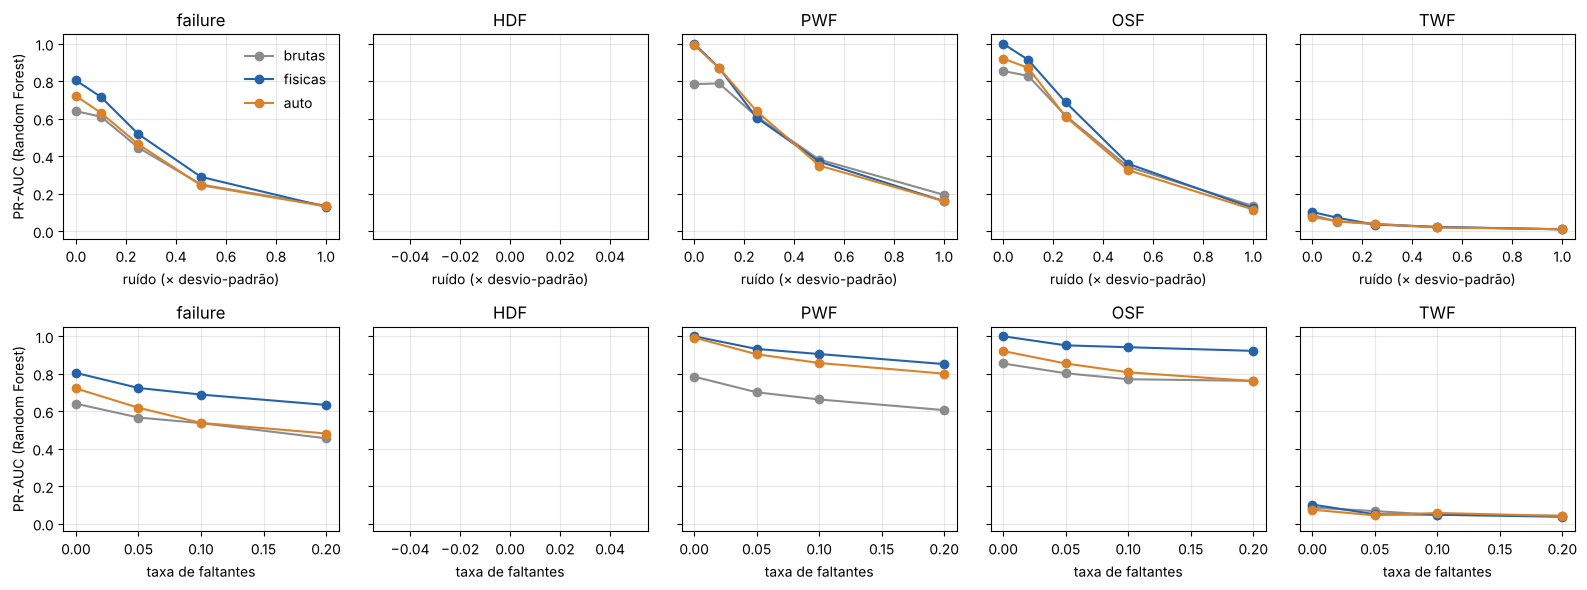

In [11]:
NIVEIS_RUIDO = [0, 0.1, 0.25, 0.5, 1.0] if not MODO_RAPIDO else [0, 0.5]
TAXAS_FALTA  = [0, 0.05, 0.10, 0.20]     if not MODO_RAPIDO else [0, 0.2]
rng = np.random.default_rng(SEED)
RUIDO_BASE = pd.DataFrame(rng.standard_normal((len(df), len(SENSORES))), columns=SENSORES)
MASCARA_BASE = pd.DataFrame(rng.random((len(df), len(SENSORES))), columns=SENSORES)
desvios = DADOS[SENSORES].std()

def dados_ruido(nivel):
    X = DADOS.copy(); X[SENSORES] = X[SENSORES] + nivel * RUIDO_BASE.values * desvios.values; return X
def dados_falta(taxa):
    X = DADOS.copy(); X[SENSORES] = X[SENSORES].mask(MASCARA_BASE < taxa); return X

def comb_rob(niveis, nome):
    return [{'alvo': a, 'protocolo': p, 'divisao': d, nome: n, 'representacao': r, 'modelo': m}
            for (a, p, d) in mapa_div if p == 'temporal'
            for n in niveis for r in REPS for m in ['Árvore rasa', 'Random Forest']]

cache = {}
def f_rob(c, chave, gerador):
    if (chave, c[chave]) not in cache: cache[(chave, c[chave])] = gerador(c[chave])
    X = cache[(chave, c[chave])]
    tr, te = mapa_div[(c['alvo'], c['protocolo'], c['divisao'])]
    return avaliar(X, df[c['alvo']].values, tr, te, 'temporal',
                   lambda n: pipeline(c['representacao'], c['modelo'], 'class_weight', n))

exp4 = rodar('exp4_ruido.csv', comb_rob(NIVEIS_RUIDO, 'ruido'), lambda c: f_rob(c, 'ruido', dados_ruido))
exp5 = rodar('exp5_faltantes.csv', comb_rob(TAXAS_FALTA, 'falta'), lambda c: f_rob(c, 'falta', dados_falta))

fig, axs = plt.subplots(2, len(ALVOS), figsize=(3.2 * len(ALVOS), 6), sharey=True)
for linha, (res, chave, rot) in enumerate([(exp4, 'ruido', 'ruído (× desvio-padrão)'), (exp5, 'falta', 'taxa de faltantes')]):
    for ax, alvo in zip(np.atleast_2d(axs)[linha], ALVOS):
        g = res[(res.alvo == alvo) & (res.modelo == 'Random Forest')].groupby([chave, 'representacao'])['PR_AUC'].mean().unstack()
        for r, cor in zip(REPS, ['#8C8C8C', '#2563A8', '#D9822B']):
            if r in g: ax.plot(g.index, g[r], 'o-', color=cor, label=r)
        ax.set_title(alvo); ax.set_xlabel(rot); ax.grid(alpha=.3)
    np.atleast_2d(axs)[linha][0].set_ylabel('PR-AUC (Random Forest)')
np.atleast_2d(axs)[0][0].legend(frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'fig_exp4_5_robustez.png'), dpi=200); plt.show()

## Experimento 6 — Ajuste de hiperparâmetros muda a conclusão?

Busca aleatória com validação cruzada interna (3 dobras, só no treino), comparada à configuração padrão do Exp. 1, para cada modelo e representação. Corte temporal de 70% e semente 0 do protocolo aleatório. A pergunta é se a ordem de importância dos fatores se mantém.

In [12]:
ESPACOS = {
  'Logística': {'m__C': loguniform(1e-3, 1e2)},
  'Árvore rasa': {'m__max_depth': randint(2, 9), 'm__min_samples_leaf': randint(1, 50)},
  'Random Forest': {'m__max_depth': [None, 6, 10, 16], 'm__min_samples_leaf': randint(1, 20),
                    'm__max_features': ['sqrt', 0.5, None]},
  'Gradient Boosting': {'m__learning_rate': loguniform(1e-2, 3e-1), 'm__max_leaf_nodes': randint(8, 64),
                        'm__min_samples_leaf': randint(5, 60), 'm__l2_regularization': loguniform(1e-4, 10)}}
alvos6 = [a for a in ['failure', 'PWF', 'OSF'] if a in ALVOS]
divs6 = [(a, p, d) for (a, p, d) in mapa_div if a in alvos6 and d in ('corte 70%', 'semente 0')]
combs6 = [{'alvo': a, 'protocolo': p, 'divisao': d, 'representacao': r, 'modelo': m}
          for (a, p, d) in divs6 for r in REPS for m in MODELOS]
def f_exp6(c):
    tr, te = mapa_div[(c['alvo'], c['protocolo'], c['divisao'])]
    def construtor(n):
        base = pipeline(c['representacao'], c['modelo'], 'class_weight', n)
        return RandomizedSearchCV(base, ESPACOS[c['modelo']], n_iter=N_ITER_BUSCA, scoring='average_precision',
                                  cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=-1)
    return avaliar(DADOS, df[c['alvo']].values, tr, te, c['protocolo'], construtor)
exp6 = rodar('exp6_ajuste.csv', combs6, f_exp6)
padrao = exp1[(exp1.balanceamento == 'class_weight') & exp1.divisao.isin(['corte 70%', 'semente 0']) & exp1.alvo.isin(alvos6)]
comp6 = padrao.merge(exp6, on=['alvo', 'protocolo', 'divisao', 'representacao', 'modelo'], suffixes=(' padrão', ' ajustado'))
comp6 = comp6[['alvo', 'protocolo', 'representacao', 'modelo', 'PR_AUC padrão', 'PR_AUC ajustado']].round(3)
comp6['ganho do ajuste'] = (comp6['PR_AUC ajustado'] - comp6['PR_AUC padrão']).round(3)
comp6.to_csv(os.path.join(SAIDA, 'exp6_ajuste_vs_padrao.csv'), index=False); display(comp6)
print('Ganho médio do ajuste:', comp6['ganho do ajuste'].mean().round(3),
      '| ganho médio físicas vs brutas (ajustado):',
      (comp6[comp6.representacao=='fisicas']['PR_AUC ajustado'].mean() - comp6[comp6.representacao=='brutas']['PR_AUC ajustado'].mean()).round(3))

  exp6_ajuste.csv: 20 novas combinações, 773s


  exp6_ajuste.csv: 40 novas combinações, 1602s


  exp6_ajuste.csv: 60 novas combinações, 2238s


exp6_ajuste.csv: 72 linhas (72 novas em 2547s)


,alvo,protocolo,representacao,modelo,PR_AUC padrão,PR_AUC ajustado,ganho do ajuste
0,failure,temporal,brutas,Logística,0.371,0.402,0.031
1,failure,temporal,brutas,Árvore rasa,0.314,0.395,0.081
2,failure,temporal,brutas,Random Forest,0.702,0.664,-0.038
3,failure,temporal,brutas,Gradient Boosting,0.692,0.734,0.042
4,failure,temporal,fisicas,Logística,0.372,0.422,0.050
...,...,...,...,...,...,...,...
67,OSF,aleatorio,fisicas,Gradient Boosting,1.000,1.000,0.000
68,OSF,aleatorio,auto,Logística,0.983,0.987,0.004
69,OSF,aleatorio,auto,Árvore rasa,0.836,0.995,0.159
70,OSF,aleatorio,auto,Random Forest,0.944,0.997,0.053


Ganho médio do ajuste: 0.033 | ganho médio físicas vs brutas (ajustado): 0.113


## Experimento 7 — Recuperação das regras e complexidade necessária

Para cada modo de falha, mede o MCC de uma árvore conforme a profundidade cresce (1 a 8), com variáveis brutas e com físicas. A pergunta é **quantos níveis de árvore são necessários para recuperar a regra**. Também imprime as regras de profundidade 2 com features físicas, para comparar com os limiares do gerador:
HDF: ΔT < 8,6 K e rpm < 1380 · PWF: potência < 3500 W ou > 9000 W · OSF: desgaste × torque > 11.000/12.000/13.000 (L/M/H) · TWF: desgaste entre 200 e 240 min (aleatório).

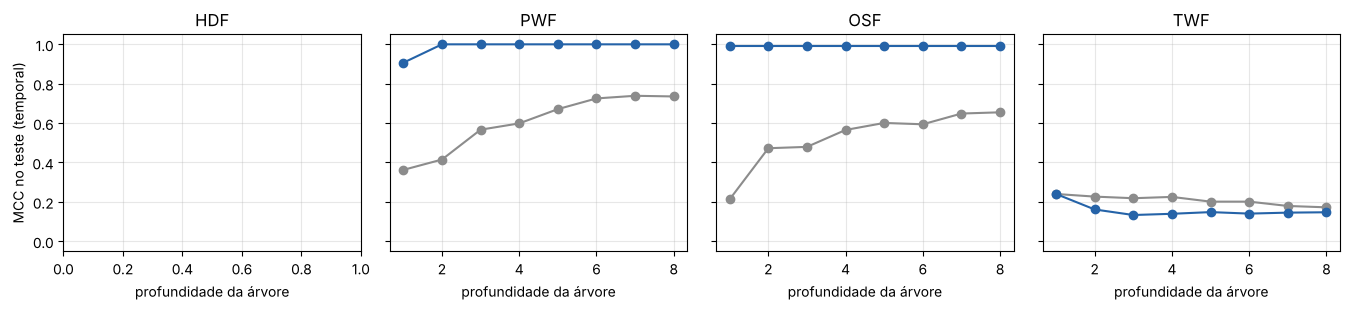


### HDF — árvore de profundidade 2, features físicas (treino = 70% iniciais)
|--- dT <= 8.7
|   |--- rpm <= 1380.0
|   |   |--- class: 1
|   |--- rpm >  1380.0
|   |   |--- class: 0
|--- dT >  8.7
|   |--- class: 0


### PWF — árvore de profundidade 2, features físicas (treino = 70% iniciais)
|--- power <= 9001.2
|   |--- power <= 3496.1
|   |   |--- class: 1
|   |--- power >  3496.1
|   |   |--- class: 0
|--- power >  9001.2
|   |--- dT <= 7.8
|   |   |--- class: 1
|   |--- dT >  7.8
|   |   |--- class: 1


### OSF — árvore de profundidade 2, features físicas (treino = 70% iniciais)
|--- strain_rel <= 1.0
|   |--- type_H <= 0.5
|   |   |--- class: 0
|   |--- type_H >  0.5
|   |   |--- class: 0
|--- strain_rel >  1.0
|   |--- class: 1


### TWF — árvore de profundidade 2, features físicas (treino = 70% iniciais)
|--- wear <= 197.5
|   |--- type_H <= 0.5
|   |   |--- class: 0
|   |--- type_H >  0.5
|   |   |--- class: 0
|--- wear >  197.5
|   |--- dT <= 10.9
|   |   |--- class: 1
|   |

In [13]:
linhas = []
modos = [a for a in ['HDF', 'PWF', 'OSF', 'TWF'] if a in ALVOS]
for alvo in modos:
    y = df[alvo].values
    for prot, rep_div, tr, te in divisoes(alvo):
        if y[te].sum() == 0 or y[tr].sum() < 6: continue
        for rep in ['brutas', 'fisicas']:
            for prof in range(1, 9):
                p = Pipeline([('rep', Representacao(rep)),
                              ('m', DecisionTreeClassifier(max_depth=prof, class_weight='balanced', random_state=SEED))])
                p.fit(DADOS.iloc[tr], y[tr])
                linhas.append({'alvo': alvo, 'protocolo': prot, 'divisao': rep_div, 'representacao': rep,
                               'profundidade': prof, 'MCC': matthews_corrcoef(y[te], p.predict(DADOS.iloc[te]))})
exp7 = pd.DataFrame(linhas); exp7.to_csv(os.path.join(SAIDA, 'exp7_complexidade.csv'), index=False)

fig, axs = plt.subplots(1, len(modos), figsize=(3.4 * len(modos), 3.2), sharey=True)
for ax, alvo in zip(np.atleast_1d(axs), modos):
    g = exp7[(exp7.alvo == alvo) & (exp7.protocolo == 'temporal')].groupby(['profundidade', 'representacao'])['MCC'].mean().unstack()
    for r, cor in [('brutas', '#8C8C8C'), ('fisicas', '#2563A8')]:
        if r in g: ax.plot(g.index, g[r], 'o-', color=cor, label=r)
    ax.set_title(alvo); ax.set_xlabel('profundidade da árvore'); ax.grid(alpha=.3); ax.set_ylim(-0.05, 1.05)
np.atleast_1d(axs)[0].set_ylabel('MCC no teste (temporal)'); np.atleast_1d(axs)[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'fig_exp7_complexidade.png'), dpi=200); plt.show()

k = int(0.7 * len(df))
for alvo in modos:
    rep = Representacao('fisicas').fit(DADOS.iloc[:k])
    arv = DecisionTreeClassifier(max_depth=2, class_weight='balanced', random_state=SEED).fit(rep.transform(DADOS.iloc[:k]), df[alvo].values[:k])
    print(f'\n### {alvo} — árvore de profundidade 2, features físicas (treino = 70% iniciais)')
    print(export_text(arv, feature_names=rep.nomes(DADOS), decimals=1))

## Experimento 8 — HDF com protocolo aleatório

Todas as 115 falhas de HDF estão num único episódio da série (registros 3.237 a 4.852), por isso o HDF não aparece em nenhum teste temporal e ficou de fora dos Exp. 2, 4, 5 e 7. Aqui esses quatro experimentos são repetidos para o HDF com a divisão aleatória (4 sementes). O ponto central é o Exp. 2: o HDF é a falha que depende de ΔT, a feature que a construção automática não destacou nos outros alvos.

In [14]:
y_hdf = df['HDF'].values
divs8 = [(p, d) for (a, p, d) in mapa_div if a == 'HDF' and p == 'aleatorio']

# 8a — circularidade: o modelo redescobre ΔT (air-proc) sem conhecimento de domínio?
linhas = []
for p, d in divs8:
    tr, te = mapa_div[('HDF', p, d)]
    sub, val = fatia_validacao(tr, y_hdf[tr], 'aleatorio')
    pipe = pipeline('auto', 'Random Forest', 'class_weight', int(y_hdf[sub].sum())).fit(DADOS.iloc[sub], y_hdf[sub])
    nomes = pipe.named_steps['rep'].nomes(DADOS)
    Xv = pipe.named_steps['rep'].transform(DADOS.iloc[val])
    imp = permutation_importance(pipe.named_steps['m'], Xv, y_hdf[val], scoring='average_precision',
                                 n_repeats=5 if not MODO_RAPIDO else 2, random_state=SEED, n_jobs=-1)
    ordem = pd.Series(imp.importances_mean, index=nomes).sort_values(ascending=False)
    pos = lambda n: int(list(ordem.index).index(n)) + 1
    linhas.append({'divisao': d, 'top 5': ', '.join(f'{n} ({v:.3f})' for n, v in ordem.head(5).items()),
                   'posição de air-proc (ΔT)': pos('air-proc'), 'posição de rpm': pos('rpm'),
                   'posição de rpm*torque': pos('rpm*torque'), 'posição de torque*wear': pos('torque*wear')})
exp8a = pd.DataFrame(linhas); exp8a.to_csv(os.path.join(SAIDA, 'exp8a_hdf_circularidade.csv'), index=False)
display(exp8a)

# 8b/8c — ruído e faltantes no protocolo aleatório
def comb_rob8(niveis, nome):
    return [{'alvo': 'HDF', 'protocolo': p, 'divisao': d, nome: n, 'representacao': r, 'modelo': m}
            for p, d in divs8 for n in niveis for r in REPS for m in ['Árvore rasa', 'Random Forest']]
def f_rob8(c, chave, gerador):
    if (chave, c[chave]) not in cache: cache[(chave, c[chave])] = gerador(c[chave])
    tr, te = mapa_div[('HDF', c['protocolo'], c['divisao'])]
    return avaliar(cache[(chave, c[chave])], y_hdf, tr, te, 'aleatorio',
                   lambda n: pipeline(c['representacao'], c['modelo'], 'class_weight', n))
exp8b = rodar('exp8b_hdf_ruido.csv', comb_rob8(NIVEIS_RUIDO, 'ruido'), lambda c: f_rob8(c, 'ruido', dados_ruido))
exp8c = rodar('exp8c_hdf_faltantes.csv', comb_rob8(TAXAS_FALTA, 'falta'), lambda c: f_rob8(c, 'falta', dados_falta))
for res, chave in [(exp8b, 'ruido'), (exp8c, 'falta')]:
    print(f'HDF — PR-AUC médio (Random Forest) por {chave}:')
    display(res[res.modelo == 'Random Forest'].groupby([chave, 'representacao'])['PR_AUC'].mean().unstack().round(3))

# 8d — complexidade necessária
linhas = []
for p, d in divs8:
    tr, te = mapa_div[('HDF', p, d)]
    for rep in ['brutas', 'fisicas']:
        for prof in range(1, 9):
            pp = Pipeline([('rep', Representacao(rep)),
                           ('m', DecisionTreeClassifier(max_depth=prof, class_weight='balanced', random_state=SEED))])
            pp.fit(DADOS.iloc[tr], y_hdf[tr])
            linhas.append({'alvo': 'HDF', 'protocolo': p, 'divisao': d, 'representacao': rep, 'profundidade': prof,
                           'MCC': matthews_corrcoef(y_hdf[te], pp.predict(DADOS.iloc[te]))})
exp8d = pd.DataFrame(linhas); exp8d.to_csv(os.path.join(SAIDA, 'exp8d_hdf_complexidade.csv'), index=False)
print('HDF — MCC médio por profundidade:')
display(exp8d.groupby(['representacao', 'profundidade'])['MCC'].mean().unstack().round(3))

,divisao,top 5,posição de air-proc (ΔT),posição de rpm,posição de rpm*torque,posição de torque*wear
0,semente 0,"air/proc (0.232), air-proc (0.107), air (0.008), air+proc (0.005), proc (0.004)",2,12,38,32
1,semente 1,"air/proc (0.172), air-proc (0.117), air+proc (0.016), air (0.016), proc (0.015)",2,21,7,18
2,semente 2,"air-proc (0.162), air/proc (0.113), air (0.051), proc-torque (0.011), air*torque (0.011)",1,46,30,32
3,semente 3,"air/proc (0.099), air-proc (0.069), air (0.011), air-torque (0.010), air*proc (0.008)",2,44,25,20


  exp8b_hdf_ruido.csv: 20 novas combinações, 15s


  exp8b_hdf_ruido.csv: 40 novas combinações, 33s


  exp8b_hdf_ruido.csv: 60 novas combinações, 52s


  exp8b_hdf_ruido.csv: 80 novas combinações, 66s


  exp8b_hdf_ruido.csv: 100 novas combinações, 83s


... (8 outputs left out)

HDF — PR-AUC médio (Random Forest) por falta:


representacao,auto,brutas,fisicas
falta,,,
0.00,0.994,0.936,0.992
0.05,0.881,0.771,0.885
0.10,0.838,0.693,0.834
0.20,0.676,0.545,0.694


HDF — MCC médio por profundidade:


profundidade,1,2,3,4,5,6,7,8
representacao,,,,,,,,
brutas,0.275,0.523,0.564,0.583,0.661,0.650,0.668,0.71
fisicas,0.372,0.946,0.949,0.941,0.959,0.974,0.971,0.97


## Análises de sensibilidade do Experimento 1

ANOVA em quatro variantes (original, sem regressão logística, PR-AUC em escala logit, e as duas juntas) e comparações pareadas (Wilcoxon com correção de Holm). Lê apenas o CSV do Exp. 1.

In [15]:
# ================================================================
# ANÁLISES DE SENSIBILIDADE DO EXPERIMENTO 1
# Autocontida: lê resultados_fatorial/exp1_fatorial.csv (não refaz nenhum modelo).
#   S1. ANOVA original (referência)
#   S2. ANOVA sem a regressão logística (ela infla o peso do fator "modelo")
#   S3. ANOVA com PR-AUC em escala logit (corrige a saturação perto de 1)
#   S4. Comparações par a par: Tukey HSD e Wilcoxon pareado com correção de Holm
# ================================================================
import os, numpy as np, pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from scipy.stats import wilcoxon

SAIDA = 'resultados_fatorial'
exp1 = pd.read_csv(os.path.join(SAIDA, 'exp1_fatorial.csv'))
ALVOS = [a for a in ['failure', 'HDF', 'PWF', 'OSF', 'TWF'] if a in exp1.alvo.unique()]
FATORES = ['protocolo', 'representacao', 'balanceamento', 'modelo']

def anova_alvo(d, metrica='PR_AUC'):
    d = d.dropna(subset=[metrica]).copy()
    d['repeticao'] = d.groupby('protocolo')['divisao'].transform(lambda s: s.astype('category').cat.codes + 1)
    fat = [f for f in FATORES if d[f].nunique() > 1]
    termos = [f'C({f})' for f in fat]
    pares = [('protocolo', 'representacao'), ('protocolo', 'modelo'), ('representacao', 'balanceamento'),
             ('representacao', 'modelo'), ('balanceamento', 'modelo')]
    termos += [f'C({a}):C({b})' for a, b in pares if a in fat and b in fat]
    if d['repeticao'].nunique() > 1:
        termos.append('C(repeticao)')
    a = anova_lm(smf.ols(f'{metrica} ~ ' + ' + '.join(termos), d).fit(), typ=2)
    a['eta2'] = a['sum_sq'] / a['sum_sq'].sum()
    a = a.drop(index=[i for i in a.index if 'repeticao' in i])
    return a.rename(index=lambda s: s.replace('C(', '').replace(')', ''))

exp1['PR_AUC_logit'] = np.log(exp1['PR_AUC'].clip(0.001, 0.999) / (1 - exp1['PR_AUC'].clip(0.001, 0.999)))

variantes = {
    'S1 original':      (exp1, 'PR_AUC'),
    'S2 sem logística': (exp1[exp1.modelo != 'Logística'], 'PR_AUC'),
    'S3 logit':         (exp1, 'PR_AUC_logit'),
    'S2+S3':            (exp1[exp1.modelo != 'Logística'], 'PR_AUC_logit'),
}

# ---------------- S1–S3: η² dos efeitos principais e da interação representação × modelo ----------------
linhas = []
for alvo in ALVOS:
    for nome, (d, met) in variantes.items():
        dd = d[d.alvo == alvo]
        if dd[met].notna().sum() < 30: continue
        a = anova_alvo(dd, met)
        lin = {'alvo': alvo, 'variante': nome}
        for termo in ['protocolo', 'representacao', 'balanceamento', 'modelo', 'representacao:modelo', 'Residual']:
            lin[termo] = round(a.loc[termo, 'eta2'], 3) if termo in a.index else np.nan
        # fator principal dominante
        principais = {k: lin[k] for k in ['protocolo', 'representacao', 'balanceamento', 'modelo'] if pd.notna(lin[k])}
        lin['fator dominante'] = max(principais, key=principais.get)
        linhas.append(lin)
sens = pd.DataFrame(linhas)
sens.to_csv(os.path.join(SAIDA, 'sens_anova_eta2.csv'), index=False)
print('η² por variante da ANOVA (efeitos principais e interação representação × modelo)')
display(sens)

print('\nO fator dominante muda entre as variantes?')
display(sens.pivot(index='alvo', columns='variante', values='fator dominante'))

# ---------------- S4a: Tukey HSD ----------------
# Atenção: o Tukey trata as observações como independentes; o teste pareado (S4b) é o mais adequado
# a este desenho, em que cada nível é comparado nas mesmas condições.
tk = []
for alvo in ALVOS:
    d = exp1[(exp1.alvo == alvo) & exp1.PR_AUC.notna()]
    for fator in ['representacao', 'balanceamento', 'modelo']:
        r = pairwise_tukeyhsd(d['PR_AUC'], d[fator])
        t = pd.DataFrame(r.summary().data[1:], columns=r.summary().data[0])
        t.insert(0, 'fator', fator); t.insert(0, 'alvo', alvo)
        tk.append(t)
tukey = pd.concat(tk, ignore_index=True)
tukey.to_csv(os.path.join(SAIDA, 'sens_tukey.csv'), index=False)

# ---------------- S4b: Wilcoxon pareado + Holm ----------------
# Cada comparação usa pares que diferem só no fator testado (mesmo alvo, protocolo, divisão e demais fatores).
def pareado(alvo, fator, a, b):
    d = exp1[(exp1.alvo == alvo) & exp1.PR_AUC.notna()]
    chaves = ['divisao'] + [f for f in FATORES if f != fator]
    w = d.pivot_table(index=chaves, columns=fator, values='PR_AUC').dropna(subset=[a, b])
    dif = w[b] - w[a]
    p = wilcoxon(dif).pvalue if (dif != 0).any() else 1.0
    return {'alvo': alvo, 'fator': fator, 'comparação': f'{b} − {a}', 'n pares': len(dif),
            'diferença mediana': round(dif.median(), 3), 'diferença média': round(dif.mean(), 3),
            '% pares em que B > A': round(100 * (dif > 0).mean(), 1), 'p': p}

comparacoes = [('representacao', 'brutas', 'fisicas'), ('representacao', 'brutas', 'auto'),
               ('representacao', 'auto', 'fisicas'),
               ('balanceamento', 'nenhum', 'smote'), ('balanceamento', 'nenhum', 'class_weight'),
               ('balanceamento', 'class_weight', 'smote'),
               ('modelo', 'Random Forest', 'Gradient Boosting'), ('modelo', 'Árvore rasa', 'Random Forest')]
pw = pd.DataFrame([pareado(alvo, *c) for alvo in ALVOS for c in comparacoes])
pw['p (Holm)'] = multipletests(pw['p'], method='holm')[1]
pw['significativo (5%)'] = np.where(pw['p (Holm)'] < 0.05, 'sim', 'não')
pw['p'] = pw['p'].map(lambda v: f'{v:.2g}'); pw['p (Holm)'] = pw['p (Holm)'].map(lambda v: f'{v:.2g}')
pw.to_csv(os.path.join(SAIDA, 'sens_wilcoxon_pareado.csv'), index=False)
print('\nComparações pareadas (Wilcoxon, correção de Holm sobre todas as comparações)')
pd.set_option('display.max_rows', 100); pd.set_option('display.width', 200)
display(pw)

print('\nArquivos salvos: sens_anova_eta2.csv, sens_tukey.csv, sens_wilcoxon_pareado.csv')

η² por variante da ANOVA (efeitos principais e interação representação × modelo)


,alvo,variante,protocolo,representacao,balanceamento,modelo,representacao:modelo,Residual,fator dominante
0,failure,S1 original,0.068,0.103,0.019,0.644,0.077,0.069,modelo
1,failure,S2 sem logística,0.094,0.274,0.032,0.388,0.067,0.111,modelo
2,failure,S3 logit,0.091,0.115,0.020,0.610,0.065,0.069,modelo
3,failure,S2+S3,0.138,0.280,0.032,0.365,0.033,0.106,modelo
4,HDF,S1 original,NaN,0.177,0.002,0.389,0.391,0.029,modelo
5,HDF,S2 sem logística,NaN,0.300,0.004,0.252,0.405,0.025,representacao
6,HDF,S3 logit,NaN,0.180,0.000,0.605,0.148,0.057,modelo
7,HDF,S2+S3,NaN,0.392,0.001,0.363,0.138,0.090,representacao
8,PWF,S1 original,0.003,0.453,0.003,0.099,0.159,0.182,representacao
9,PWF,S2 sem logística,0.000,0.645,0.005,0.026,0.098,0.168,representacao



O fator dominante muda entre as variantes?


variante,S1 original,S2 sem logística,S2+S3,S3 logit
alvo,,,,
HDF,modelo,representacao,representacao,modelo
OSF,representacao,representacao,representacao,representacao
PWF,representacao,representacao,representacao,representacao
TWF,modelo,modelo,modelo,modelo
failure,modelo,modelo,modelo,modelo



Comparações pareadas (Wilcoxon, correção de Holm sobre todas as comparações)


,alvo,fator,comparação,n pares,diferença mediana,diferença média,% pares em que B > A,p,p (Holm),significativo (5%)
0,failure,representacao,fisicas − brutas,96,0.121,0.141,85.4,4.9e-14,1.7e-12,sim
1,failure,representacao,auto − brutas,96,0.096,0.116,87.5,1.3e-14,4.6e-13,sim
2,failure,representacao,fisicas − auto,96,0.008,0.025,66.7,0.00064,0.013,sim
3,failure,balanceamento,smote − nenhum,96,-0.058,-0.059,15.6,1.7e-11,5.2e-10,sim
4,failure,balanceamento,class_weight − nenhum,96,-0.012,-0.007,36.5,0.0082,0.13,não
5,failure,balanceamento,smote − class_weight,96,-0.029,-0.053,7.3,4.6e-15,1.6e-13,sim
6,failure,modelo,Gradient Boosting − Random Forest,72,0.019,0.030,70.8,5.1e-06,0.00013,sim
7,failure,modelo,Random Forest − Árvore rasa,72,0.231,0.195,97.2,2.2e-13,7.3e-12,sim
8,HDF,representacao,fisicas − brutas,48,0.021,0.130,64.6,3.8e-05,0.00092,sim
9,HDF,representacao,auto − brutas,48,0.022,0.126,79.2,2.5e-07,7.1e-06,sim



Arquivos salvos: sens_anova_eta2.csv, sens_tukey.csv, sens_wilcoxon_pareado.csv


## Balanceamento com métricas que dependem do limiar (MCC e F1)

In [16]:
# ================================================================
# BALANCEAMENTO: A CONCLUSÃO SE MANTÉM COM MÉTRICAS QUE DEPENDEM DO LIMIAR?
# O PR-AUC mede ordenação; o balanceamento atua sobretudo na calibração e no limiar.
# Aqui as mesmas comparações pareadas são repetidas com MCC e F1, calculados no limiar
# escolhido na validação (lembrete: o limiar é otimizado por F1 em cada combinação).
# Autocontida: lê resultados_fatorial/exp1_fatorial.csv.
# ================================================================
import os, numpy as np, pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

SAIDA = 'resultados_fatorial'
exp1 = pd.read_csv(os.path.join(SAIDA, 'exp1_fatorial.csv'))
ALVOS = [a for a in ['failure', 'HDF', 'PWF', 'OSF', 'TWF'] if a in exp1.alvo.unique()]
FATORES = ['protocolo', 'representacao', 'balanceamento', 'modelo']
METRICAS = ['PR_AUC', 'MCC', 'F1']

def pareado(d, alvo, fator, a, b, metrica):
    d = d[(d.alvo == alvo) & d[metrica].notna()]
    chaves = ['divisao'] + [f for f in FATORES if f != fator]
    w = d.pivot_table(index=chaves, columns=fator, values=metrica).dropna(subset=[a, b])
    dif = w[b] - w[a]
    p = wilcoxon(dif).pvalue if (dif != 0).any() else 1.0
    return {'alvo': alvo, 'métrica': metrica, 'comparação': f'{b} − {a}', 'n': len(dif),
            'dif. mediana': dif.median(), 'dif. média': dif.mean(),
            '% pares B > A': 100 * (dif > 0).mean(), 'p': p}

comps = [('nenhum', 'smote'), ('nenhum', 'class_weight'), ('class_weight', 'smote')]

# ---------- 1. Todos os modelos juntos ----------
linhas = [pareado(exp1, alvo, 'balanceamento', a, b, m) for m in METRICAS for alvo in ALVOS for a, b in comps]
res = pd.DataFrame(linhas)
res['p (Holm)'] = multipletests(res['p'], method='holm')[1]
res['sig.'] = np.where(res['p (Holm)'] < 0.05, '✓', '')

def resumo(t):
    t = t.copy()
    t['célula'] = t.apply(lambda r: f"{r['dif. mediana']:+.3f} ({r['% pares B > A']:.0f}%) {r['sig.']}", axis=1)
    return t.pivot_table(index=['comparação', 'métrica'], columns='alvo', values='célula', aggfunc='first')[ALVOS]

print('1) Balanceamento — todos os modelos juntos')
print('   célula = diferença mediana (% de pares em que o 1º nível supera o 2º), ✓ = significativo após Holm')
display(resumo(res))
res.to_csv(os.path.join(SAIDA, 'balanceamento_metricas.csv'), index=False)

# ---------- 2. Por modelo (o efeito do balanceamento depende do modelo?) ----------
lin2 = []
for mod in sorted(exp1.modelo.unique()):
    sub = exp1[exp1.modelo == mod]
    for m in ['MCC', 'PR_AUC']:
        for alvo in ALVOS:
            for a, b in comps:
                r = pareado(sub, alvo, 'balanceamento', a, b, m); r['modelo'] = mod; lin2.append(r)
res2 = pd.DataFrame(lin2)
res2['p (Holm)'] = multipletests(res2['p'], method='holm')[1]
res2['sig.'] = np.where(res2['p (Holm)'] < 0.05, '✓', '')
res2.to_csv(os.path.join(SAIDA, 'balanceamento_por_modelo.csv'), index=False)
print('\n2) MCC: SMOTE − nenhum e class_weight − nenhum, por modelo')
t2 = res2[(res2['métrica'] == 'MCC') & res2['comparação'].isin(['smote − nenhum', 'class_weight − nenhum'])].copy()
t2['célula'] = t2.apply(lambda r: f"{r['dif. mediana']:+.3f} ({r['% pares B > A']:.0f}%) {r['sig.']}", axis=1)
display(t2.pivot_table(index=['modelo', 'comparação'], columns='alvo', values='célula', aggfunc='first')[ALVOS])

# ---------- 3. Médias por nível ----------
print('\n3) Médias por balanceamento (todos os modelos)')
display(exp1.groupby(['alvo', 'balanceamento'])[METRICAS].mean().round(3).unstack('balanceamento'))

# ---------- 4. Veredito automático ----------
print('\n4) Veredito: em quantos alvos cada técnica é significativamente melhor / pior que não balancear')
for m in METRICAS:
    for comp in ['smote − nenhum', 'class_weight − nenhum']:
        t = res[(res['métrica'] == m) & (res['comparação'] == comp)]
        melhor = t[(t['sig.'] == '✓') & (t['dif. mediana'] > 0)].alvo.tolist()
        pior = t[(t['sig.'] == '✓') & (t['dif. mediana'] < 0)].alvo.tolist()
        print(f'  {m:6s} {comp:24s} melhor em {melhor or "nenhum"} | pior em {pior or "nenhum"}')

1) Balanceamento — todos os modelos juntos
   célula = diferença mediana (% de pares em que o 1º nível supera o 2º), ✓ = significativo após Holm


alvo                                  failure            HDF             PWF             OSF             TWF
comparação            métrica                                                                               
class_weight − nenhum F1        -0.009 (43%)   +0.000 (38%)    +0.000 (35%)    +0.000 (35%)   -0.002 (26%) ✓
                      MCC       -0.013 (41%)   +0.000 (38%)    +0.000 (35%)    +0.000 (34%)   -0.003 (36%) ✓
                      PR_AUC    -0.012 (36%)   +0.000 (29%)    +0.000 (49%)    +0.000 (46%)    -0.002 (46%) 
smote − class_weight  F1       -0.046 (16%) ✓  +0.000 (27%)    +0.000 (46%)    +0.000 (41%)    +0.000 (36%) 
                      MCC      -0.038 (17%) ✓  +0.000 (25%)    +0.000 (46%)    +0.000 (42%)    +0.000 (47%) 
                      PR_AUC    -0.029 (7%) ✓  +0.000 (42%)   +0.002 (55%) ✓  +0.000 (52%) ✓   -0.002 (42%) 
smote − nenhum        F1       -0.055 (24%) ✓  -0.001 (35%)    +0.000 (38%)    +0.000 (42%)   -0.011 (24%) ✓
                      MCC      -0.060 (23%) ✓  -0.000 (35%)    +0.000 (39%)    +0.000 (43%)    -0.001 (47%) 
                      PR_AUC   -0.058 (16%) ✓  -0.001 (21%)    +0.000 (50%)    +0.000 (51%)   -0.008 (32%) ✓


2) MCC: SMOTE − nenhum e class_weight − nenhum, por modelo


alvo                                            failure            HDF            PWF            OSF            TWF
modelo            comparação                                                                                       
Gradient Boosting class_weight − nenhum   +0.030 (71%)    +0.000 (8%)   +0.121 (79%)   +0.014 (54%)   -0.001 (42%) 
                  smote − nenhum          -0.002 (46%)   +0.000 (33%)   +0.094 (67%)   +0.010 (67%)   -0.002 (42%) 
Logística         class_weight − nenhum   -0.019 (21%)   +0.017 (67%)   -0.085 (8%) ✓  +0.000 (38%)   +0.001 (50%) 
                  smote − nenhum          -0.043 (17%)   +0.004 (50%)   -0.069 (21%)   +0.004 (54%)   +0.001 (54%) 
Random Forest     class_weight − nenhum   -0.018 (33%)   -0.005 (25%)   +0.000 (46%)   +0.000 (33%)   -0.004 (42%) 
                  smote − nenhum         -0.101 (17%) ✓   -0.028 (8%)   +0.024 (58%)   +0.000 (38%)   -0.022 (46%) 
Árvore rasa       class_weight − nenhum   -0.024 (38%)   +0.003 (50%)    +0.000 (8%)   +0.000 (12%)   -0.164 (12%) 
                  smote − nenhum         -0.102 (12%) ✓  +0.001 (50%)    +0.000 (8%)   +0.000 (12%)   -0.059 (46%)


3) Médias por balanceamento (todos os modelos)


PR_AUC                        MCC                         F1              
balanceamento class_weight nenhum  smote class_weight nenhum  smote class_weight nenhum  smote
alvo                                                                                          
HDF                  0.893  0.909  0.896        0.839  0.850  0.813        0.832  0.843  0.804
OSF                  0.915  0.933  0.927        0.876  0.883  0.844        0.871  0.880  0.836
PWF                  0.883  0.898  0.896        0.835  0.843  0.805        0.823  0.837  0.795
TWF                  0.089  0.096  0.081        0.081  0.121  0.096        0.064  0.095  0.070
failure              0.658  0.664  0.605        0.633  0.645  0.574        0.626  0.631  0.562


4) Veredito: em quantos alvos cada técnica é significativamente melhor / pior que não balancear
  PR_AUC smote − nenhum           melhor em nenhum | pior em ['failure', 'TWF']
  PR_AUC class_weight − nenhum    melhor em nenhum | pior em nenhum
  MCC    smote − nenhum           melhor em nenhum | pior em ['failure']
  MCC    class_weight − nenhum    melhor em nenhum | pior em ['TWF']
  F1     smote − nenhum           melhor em nenhum | pior em ['failure', 'TWF']
  F1     class_weight − nenhum    melhor em nenhum | pior em ['TWF']


## Resumo e arquivos gerados

In [17]:
print('Arquivos em', SAIDA)
for f in sorted(os.listdir(SAIDA)): print(' ', f)
d = exp1[exp1.alvo == 'failure']
print('\nFalha agregada — PR-AUC médio por fator:')
for fator in ['protocolo', 'representacao', 'balanceamento', 'modelo']:
    print(' ', fator, d.groupby(fator)['PR_AUC'].mean().round(3).to_dict())

Arquivos em resultados_fatorial
  autocorrelacao.csv
  balanceamento_metricas.csv
  balanceamento_por_modelo.csv
  exp1_anova_eta2.csv
  exp1_fatorial.csv
  exp1_ganho_por_protocolo.csv
  exp2_circularidade.csv
  exp3_ablacao.csv
  exp3_ablacao_resumo.csv
  exp4_ruido.csv
  exp5_faltantes.csv
  exp6_ajuste.csv
  exp6_ajuste_vs_padrao.csv
  exp7_complexidade.csv
  exp8a_hdf_circularidade.csv
  exp8b_hdf_ruido.csv
  exp8c_hdf_faltantes.csv
  exp8d_hdf_complexidade.csv
  fig_exp1_eta2.png
  fig_exp1_interacao.png
  fig_exp4_5_robustez.png
  fig_exp7_complexidade.png
  sens_anova_eta2.csv
  sens_tukey.csv
  sens_wilcoxon_pareado.csv

Falha agregada — PR-AUC médio por fator:
  protocolo {'aleatorio': 0.692, 'temporal': 0.592}
  representacao {'auto': 0.673, 'brutas': 0.557, 'fisicas': 0.697}
  balanceamento {'class_weight': 0.658, 'nenhum': 0.664, 'smote': 0.605}
  modelo {'Gradient Boosting': 0.801, 'Logística': 0.422, 'Random Forest': 0.77, 'Árvore rasa': 0.576}
